# 05 · 自回归采样：temperature 与 top-k

**Source audit:** [karpathy/nanoGPT](https://github.com/karpathy/nanoGPT/tree/3adf61e154c3fe3fca428ad6bc3818b27a3b8291) at `3adf61e154c3`; relevant files: `model.py`, `train.py`, `sample.py`, `data/shakespeare_char/prepare.py`, `config/train_shakespeare_char.py`.

**Scope:** The notebook uses a small **educational adaptation** (`nanogpt_edu.py`) consistent with the original architecture, not a verbatim copy of the full upstream training program. No pretrained weights, external datasets, downloads, distributed GPUs, or performance reproduction are claimed. Figures and prints are generated by real local CPU executions. The project's README has marked nanoGPT deprecated since Nov 2025 and points to nanochat.

## 基于训练模型生成文本

对应上游 `sample.py` 和 `model.py/GPT.generate`。循环：取最近 `block_size` 个 token → 仅预测末位 → 温度缩放 → 可选 top-k → multinomial 采样 → append token。由于训练语料小、步骤少，生成内容只是教学演示。

In [1]:
from pathlib import Path
import sys, torch, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
# Compatible with starting Jupyter from the notebook directory OR repository root.
P = Path.cwd().resolve()
ROOT = P if (P / 'nanogpt_edu.py').exists() else P.parent
if not (ROOT / 'nanogpt_edu.py').exists():
    raise RuntimeError('Open this notebook from tutorials/nanogpt/notebooks or the tutorials/nanogpt directory')
sys.path.insert(0, str(ROOT))
from nanogpt_edu import GPTConfig, GPT, char_dataset, get_batch, training_text, lr_schedule, parameter_groups
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(2, torch.get_num_threads()))
torch.manual_seed(42); np.random.seed(42)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| CPU tutorial', '| path:', ROOT)

Python: 3.13.5 | PyTorch: 2.10.0+cpu | CPU tutorial | path: /mnt/notebook-builder/tutorials/nanogpt


In [2]:
from dataclasses import asdict
ckpt=OUT/'nanogpt_tiny_checkpoint.pt'
if ckpt.exists():
    state=torch.load(ckpt,map_location='cpu',weights_only=True)
    cfg=GPTConfig(**state['config'])
    stoi,itos=state['stoi'],state['itos']
    model=GPT(cfg)
    model.load_state_dict(state['model']); model.eval()
    print('Loaded trusted local tutorial checkpoint:',ckpt)
else:
    # Standalone path: generate a short local checkpoint if notebook 04 has not run.
    ids,stoi,itos=char_dataset(training_text(repeats=12))
    cfg=GPTConfig(vocab_size=len(stoi),block_size=24,n_layer=1,n_head=2,n_embd=32)
    model=GPT(cfg);optim=torch.optim.AdamW(model.parameters(),lr=3e-3)
    for step in range(35):
        x,y=get_batch(ids,cfg.block_size,8)
        optim.zero_grad(set_to_none=True);_,loss=model(x,y);loss.backward();optim.step()
    model.eval()
    print('No checkpoint: trained a standalone 35-step educational model')
print('vocab:',len(stoi),'block_size:',cfg.block_size)

Loaded trusted local tutorial checkpoint: /mnt/notebook-builder/tutorials/nanogpt/outputs/nanogpt_tiny_checkpoint.pt
vocab: 27 block_size: 24


Prompt: 'the ' IDs: [[23, 12, 9, 1]]
--- temperature 0.6 / top_k=10 ---
'the .\nstllle rn loooke rn.ws tomena toll tftare ton tom fttioon  t tonstoon tone ra trme plle '
--- temperature 1.0 / top_k=10 ---
'the .\n\nwetlernealoookl rm ws tomena t ll tftare tontane fttioon ro ton lmon s te ra trmiins r '
--- temperature 1.4 / top_k=10 ---
'the .\n\nwellerneonoatolne rimras tia t ls.we mle towtane ftle oe ro fornlmok tooe.\na trmiinslr '


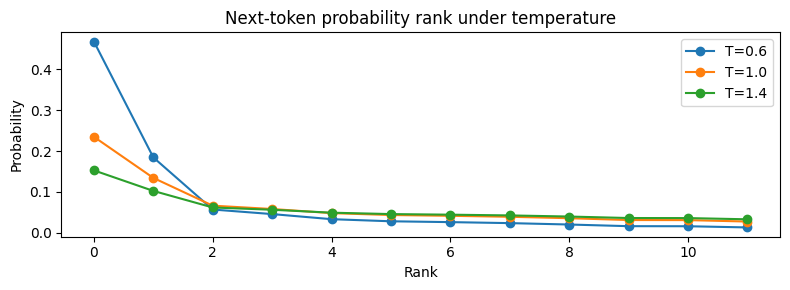

In [3]:
prompt='the '
encoded=torch.tensor([[stoi[ch] for ch in prompt]],dtype=torch.long)
print('Prompt:',repr(prompt),'IDs:',encoded.tolist())
for temp in [0.6,1.0,1.4]:
    torch.manual_seed(2026)
    tokens=model.generate(encoded,max_new_tokens=90,temperature=temp,top_k=10)[0].tolist()
    generated=''.join(itos[int(t)] for t in tokens)
    print(f'--- temperature {temp} / top_k=10 ---')
    print(repr(generated[:120]))
assert len(tokens)==encoded.numel()+90
fig,ax=plt.subplots(figsize=(8,3))
with torch.no_grad(): raw_logits,_=model(encoded)
raw=raw_logits[0,-1,:]
for temp in [.6,1.0,1.4]:
    probs=torch.softmax(raw/temp,dim=-1)
    ax.plot(torch.sort(probs,descending=True).values[:12].numpy(),marker='o',label=f'T={temp}')
ax.set_title('Next-token probability rank under temperature');ax.set_xlabel('Rank');ax.set_ylabel('Probability');ax.legend();fig.tight_layout()
fig.savefig(FIG/'05_temperature.png',dpi=130);display(fig);plt.close(fig)

Top 10 possible next characters:
   1. 't'   : 0.2350
   2. ' '   : 0.1344
   3. '.'   : 0.0665
   4. 'r'   : 0.0583
   5. 'f'   : 0.0482
   6. 'a'   : 0.0436
   7. 'l'   : 0.0417
   8. 's'   : 0.0393
   9. 'p'   : 0.0358
  10. 'w'   : 0.0313


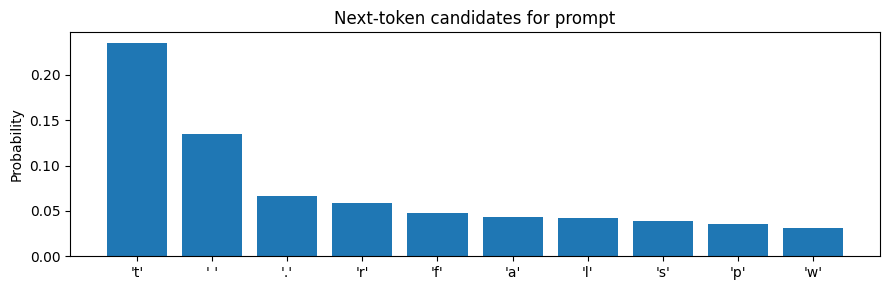

In [4]:
probs=torch.softmax(raw,dim=-1)
vals,indices=torch.topk(probs,10)
print('Top 10 possible next characters:')
for i,(idx,prob) in enumerate(zip(indices.tolist(),vals.tolist())):
    print(f'  {i+1:2d}. {repr(itos[idx]):5s} : {prob:.4f}')
fig,ax=plt.subplots(figsize=(9,3));ax.bar([repr(itos[idx]) for idx in indices.tolist()],vals.tolist());ax.set_ylabel('Probability');ax.set_title('Next-token candidates for prompt');fig.tight_layout()
fig.savefig(FIG/'05_top_tokens.png',dpi=130);display(fig);plt.close(fig)

### 练习

去掉 `top_k=10` 或把 temperature 降到 `0.3`，观察多样性。注意：这是从 **训练所得权重** 中采样，不是 GPT-2 预训练权重；不应把随机生成字符视为模型具备真实语义推理能力。